In [19]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from lightgbm import early_stopping

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping

# Create the dataset

In [20]:
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)

In [21]:
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (1000, 2)
Labels shape: (1000,)


# Visualize the data

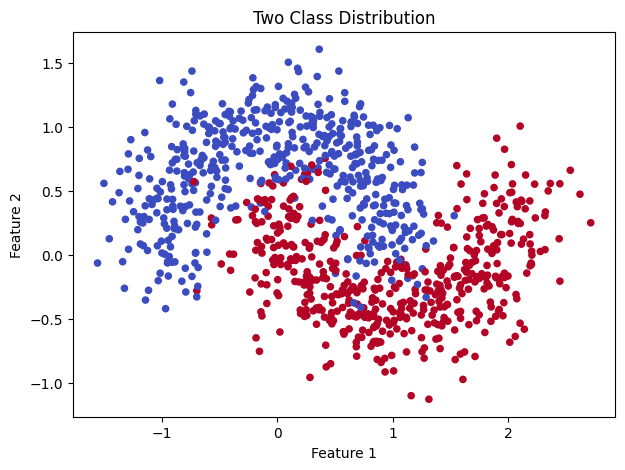

In [22]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap="coolwarm")
plt.title("Two Class Distribution")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Split the dataset

In [23]:
# First reserve 20% of the data for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [24]:
print(X_train_val.shape)
print(X_test.shape)
print(y_train_val.shape)
print(y_test.shape)

(800, 2)
(200, 2)
(800,)
(200,)


In [25]:
# Split the remaining 800 rows into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

In [26]:
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

Training examples: 600
Validation examples: 200
Test examples: 200


# Scale the input features

In [27]:
scaler = StandardScaler()

# fit_transform() learns the feature means and standard deviations from the training set, then scales it.
# transform() applies those same statistics to the validation and test sets.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =  scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

# Build the neural network with dropout

In [28]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(2,)),      # Accepts two input features

    Dense(64, activation="relu"),   # Learns patterns using 64  neurons
    Dropout(0.3),   # Randomly sets about 30% of the preceding activations to zero during training

    Dense(64, activation="relu"),   # Learns more complex patterns
    Dropout(0.3),       # Applies dropout again

    Dense(1, activation="sigmoid")  # Produces a probability for binary classification.
])

In [29]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

# Compile the model

In [30]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Add Early Stopping

In [31]:
# This callback works alongside dropout
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the neural network

In [32]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs = 200,
    batch_size= 32,
    validation_data = (X_val_scaled, y_val),    # Evaluates the model on validation data after each epoch.
    callbacks = [early_stopping],   # Activates our early-stopping rule.
    verbose=1
)

Epoch 1/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7517 - loss: 0.5975 - val_accuracy: 0.8200 - val_loss: 0.5075
Epoch 2/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8433 - loss: 0.4558 - val_accuracy: 0.8200 - val_loss: 0.4062
Epoch 3/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8483 - loss: 0.3641 - val_accuracy: 0.8200 - val_loss: 0.3709
Epoch 4/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8500 - loss: 0.3446 - val_accuracy: 0.8200 - val_loss: 0.3664
Epoch 5/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8517 - loss: 0.3254 - val_accuracy: 0.8200 - val_loss: 0.3652
Epoch 6/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8517 - loss: 0.3219 - val_accuracy: 0.8100 - val_loss: 0.3633
Epoch 7/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8550 - loss: 0.3070 - val_accuracy: 0.8100 - val_loss: 0.3612
Epoch 8/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8583 - loss: 0.3078 - val_accuracy: 0.8200 - 

# Visualize the training results

How should you interpret the plot?
- If training loss decreases, the model is improving its fit to the training data.
- If validation loss also decreases, performance on unseen validation examples is improving.
- If training loss continues decreasing while validation loss rises, that can indicate overfitting.
- Early stopping can stop training when validation loss fails to improve for the specified patience period.
Dropout doesn't guarantee that validation loss will always decrease or that overfitting will never happen.

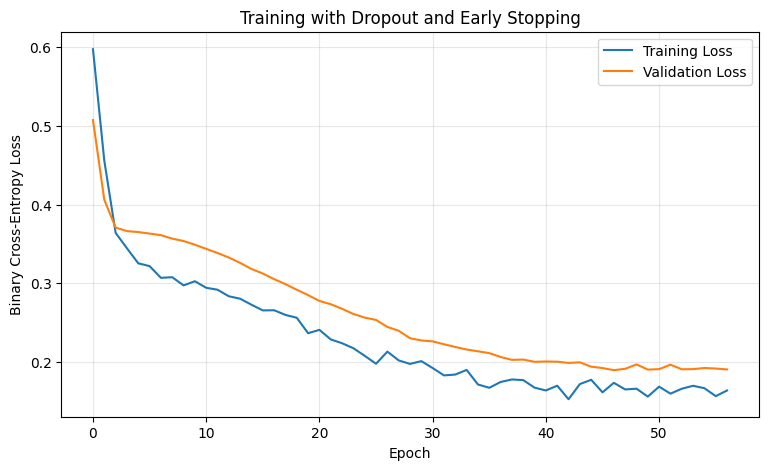

In [33]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training with Dropout and Early Stopping")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Find the best epoch

In [34]:
epochs_completed = len(history.history["loss"])

best_epoch = np.argmin(history.history["val_loss"]) + 1
print("Epochs completed:", epochs_completed)
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

Epochs completed: 57
Best epoch: 47
Best validation loss: 0.1896682232618332


# Evaluate the final model on the test set

In [35]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss: 0.0964
Test Accuracy: 97.00%
